In [1]:
class MultivariateLinearRegression:
  def __init__(self, learning_rate=0.01, iterations=1000):
    self.lr = learning_rate
    self.iterations = iterations
    self.weights = []  #<-- now a list for multivariate
    self.bias = None
    self.cost_history = []
    
  def predict(self, X):
    
    total = self.bias
    for j in range(len(self.weights)):
      total += self.weights[j] * X[j]
      
    return total
    
  def fit(self, X, y):
    n_samples = len(X)
    n_features = len(X[0])
    
    self.weights = [0.0] * n_features  #<-- initialize weights for each feature
    self.bias = 0.0
    
    for _ in range(self.iterations):
      
      gradient_w = [0.0] * n_features  #<-- gradient for each weight
      gradient_b = 0.0
      
      current_cost = 0.0
      
      for i in range(n_samples):
        
        y_pred = self.predict(X[i])
        error = y_pred - y[i]
        
        current_cost += error ** 2
        
        gradient_b += error
        
        for k in range(n_features):
          gradient_w[k] += error * X[i][k]
          
      self.cost_history.append((1/ (2 * n_samples)) * current_cost)
      
      gradient_b /= n_samples
      self.bias -= self.lr * gradient_b
      
      for k in range(n_features):
        gradient_w[k] /= n_samples
        self.weights[k] -= self.lr * gradient_w[k]

Final Weights: [0.8503801342201055, 0.9272322355890144]
Final Bias: -0.425941868560813
Predicted Price for [2.5, 3]: 4.4817051737564935


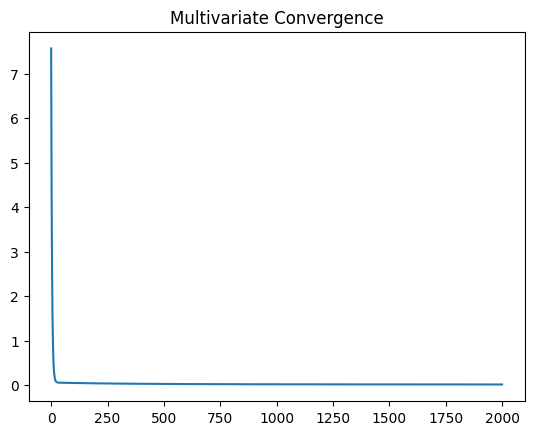

In [2]:
# --- DATA SETUP ---
# X = [[Size, Rooms], [Size, Rooms]...]
# Note: I scaled these numbers down (e.g., 2.1 = 2100 sqft) to keep math stable for raw gradient descent
X_train = [
    [2.1, 3], 
    [1.5, 2],
    [3.0, 4],
    [1.0, 1]
]

# y = Price (in 100k)
y_train = [4.0, 2.5, 6.0, 1.5] 

# --- RUNNING THE WIZARD MODEL ---
model = MultivariateLinearRegression(learning_rate=0.01, iterations=2000)
model.fit(X_train, y_train)

# --- RESULTS ---
print(f"Final Weights: {model.weights}")
print(f"Final Bias: {model.bias}")

# Test Prediction: 2500 sqft (2.5) with 3 rooms
new_house = [2.5, 3]
price = model.predict(new_house)
print(f"Predicted Price for {new_house}: {price}")

# Check Cost Curve
import matplotlib.pyplot as plt
plt.plot(model.cost_history)
plt.title("Multivariate Convergence")
plt.show()